# ML Lab End Sem — Execution Solutions
### All 5 Topics | Functions Only | No sklearn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

---
## PAPER 1 — Naive Bayes

In [3]:
data_nb = [
    {'Outlook':'Sunny',    'Temperature':'Hot',  'Humidity':'High',   'Wind':'Weak',   'PlayTennis':'No'},
    {'Outlook':'Sunny',    'Temperature':'Hot',  'Humidity':'High',   'Wind':'Strong', 'PlayTennis':'No'},
    {'Outlook':'Overcast', 'Temperature':'Hot',  'Humidity':'High',   'Wind':'Weak',   'PlayTennis':'Yes'},
    {'Outlook':'Rain',     'Temperature':'Mild', 'Humidity':'High',   'Wind':'Weak',   'PlayTennis':'Yes'},
    {'Outlook':'Rain',     'Temperature':'Cool', 'Humidity':'Normal', 'Wind':'Weak',   'PlayTennis':'Yes'},
    {'Outlook':'Rain',     'Temperature':'Cool', 'Humidity':'Normal', 'Wind':'Strong', 'PlayTennis':'No'},
    {'Outlook':'Overcast', 'Temperature':'Cool', 'Humidity':'Normal', 'Wind':'Strong', 'PlayTennis':'Yes'},
    {'Outlook':'Sunny',    'Temperature':'Mild', 'Humidity':'High',   'Wind':'Weak',   'PlayTennis':'No'},
    {'Outlook':'Sunny',    'Temperature':'Cool', 'Humidity':'Normal', 'Wind':'Weak',   'PlayTennis':'Yes'},
    {'Outlook':'Rain',     'Temperature':'Mild', 'Humidity':'Normal', 'Wind':'Weak',   'PlayTennis':'Yes'},
    {'Outlook':'Sunny',    'Temperature':'Mild', 'Humidity':'Normal', 'Wind':'Strong', 'PlayTennis':'Yes'},
    {'Outlook':'Overcast', 'Temperature':'Mild', 'Humidity':'High',   'Wind':'Strong', 'PlayTennis':'Yes'},
    {'Outlook':'Overcast', 'Temperature':'Hot',  'Humidity':'Normal', 'Wind':'Weak',   'PlayTennis':'Yes'},
    {'Outlook':'Rain',     'Temperature':'Mild', 'Humidity':'High',   'Wind':'Strong', 'PlayTennis':'No'},
]

In [4]:
def compute_priors(data, label_col):
    total = len(data)
    counts = Counter(row[label_col] for row in data)
    return {cls: count / total for cls, count in counts.items()}

priors = compute_priors(data_nb, 'PlayTennis')
print(priors)

{'No': 0.35714285714285715, 'Yes': 0.6428571428571429}


In [5]:
def compute_likelihoods(data, label_col, k=0):
    features = [key for key in data[0] if key != label_col]
    classes  = list(set(row[label_col] for row in data))
    likelihoods = {}
    for feature in features:
        likelihoods[feature] = {}
        values = list(set(row[feature] for row in data))
        for val in values:
            likelihoods[feature][val] = {}
            for cls in classes:
                cls_rows  = [row for row in data if row[label_col] == cls]
                match     = sum(1 for row in cls_rows if row[feature] == val)
                likelihoods[feature][val][cls] = (match + k) / (len(cls_rows) + k * len(values))
    return likelihoods

likelihoods = compute_likelihoods(data_nb, 'PlayTennis')
print(likelihoods['Outlook'])

{'Sunny': {'No': 0.6, 'Yes': 0.2222222222222222}, 'Overcast': {'No': 0.0, 'Yes': 0.4444444444444444}, 'Rain': {'No': 0.4, 'Yes': 0.3333333333333333}}


In [6]:
def naive_bayes_predict(instance, priors, likelihoods):
    scores = {}
    for cls, prior in priors.items():
        score = prior
        for feature, val in instance.items():
            score *= likelihoods[feature].get(val, {}).get(cls, 1e-9)
        scores[cls] = score
    return max(scores, key=scores.get), scores

instance = {'Outlook':'Sunny', 'Temperature':'Cool', 'Humidity':'High', 'Wind':'Strong'}
pred, scores = naive_bayes_predict(instance, priors, likelihoods)
print('Prediction:', pred)
print('Scores:', scores)

Prediction: No
Scores: {'No': 0.02057142857142857, 'Yes': 0.005291005291005291}


In [7]:
def evaluate_nb(data, label_col, k=0):
    correct = 0
    preds   = []
    classes = list(set(row[label_col] for row in data))
    conf    = {c: {c2: 0 for c2 in classes} for c in classes}
    for i in range(len(data)):
        train = data[:i] + data[i+1:]
        test  = data[i]
        p  = compute_priors(train, label_col)
        lh = compute_likelihoods(train, label_col, k=k)
        instance = {key: val for key, val in test.items() if key != label_col}
        pred, _  = naive_bayes_predict(instance, p, lh)
        preds.append(pred)
        actual = test[label_col]
        conf[actual][pred] += 1
        if pred == actual:
            correct += 1
    acc = correct / len(data)
    print(f'Accuracy (k={k}): {acc:.2%}')
    print('Confusion Matrix:', conf)
    return acc

evaluate_nb(data_nb, 'PlayTennis')

Accuracy (k=0): 57.14%
Confusion Matrix: {'No': {'No': 1, 'Yes': 4}, 'Yes': {'No': 2, 'Yes': 7}}


0.5714285714285714

Accuracy (k=0): 57.14%
Confusion Matrix: {'No': {'No': 1, 'Yes': 4}, 'Yes': {'No': 2, 'Yes': 7}}
Accuracy (k=1): 50.00%
Confusion Matrix: {'No': {'No': 1, 'Yes': 4}, 'Yes': {'No': 3, 'Yes': 6}}
Accuracy (k=2): 50.00%
Confusion Matrix: {'No': {'No': 1, 'Yes': 4}, 'Yes': {'No': 3, 'Yes': 6}}
Accuracy (k=3): 50.00%
Confusion Matrix: {'No': {'No': 1, 'Yes': 4}, 'Yes': {'No': 3, 'Yes': 6}}
Accuracy (k=4): 64.29%
Confusion Matrix: {'No': {'No': 1, 'Yes': 4}, 'Yes': {'No': 1, 'Yes': 8}}
Accuracy (k=5): 64.29%
Confusion Matrix: {'No': {'No': 0, 'Yes': 5}, 'Yes': {'No': 0, 'Yes': 9}}


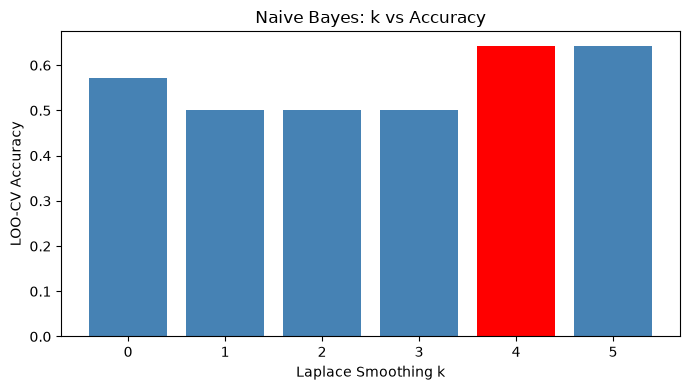

Best k = 4


In [8]:
def plot_k_vs_accuracy(data, label_col):
    k_vals = list(range(6))
    accs   = [evaluate_nb(data, label_col, k=k) for k in k_vals]
    best_k = k_vals[accs.index(max(accs))]
    colors = ['red' if k == best_k else 'steelblue' for k in k_vals]
    plt.figure(figsize=(7, 4))
    plt.bar(k_vals, accs, color=colors)
    plt.xlabel('Laplace Smoothing k')
    plt.ylabel('LOO-CV Accuracy')
    plt.title('Naive Bayes: k vs Accuracy')
    plt.xticks(k_vals)
    plt.tight_layout()
    plt.show()
    print(f'Best k = {best_k}')

plot_k_vs_accuracy(data_nb, 'PlayTennis')

---
## PAPER 2 — KNN

In [9]:
points_knn = np.array([[15,39],[16,81],[17,6],[19,77],[25,40],[26,70],[30,88],[35,29],[45,85],[55,52]], dtype=float)
labels_knn = ['Low','High','Low','High','Low','High','High','Low','High','Low']

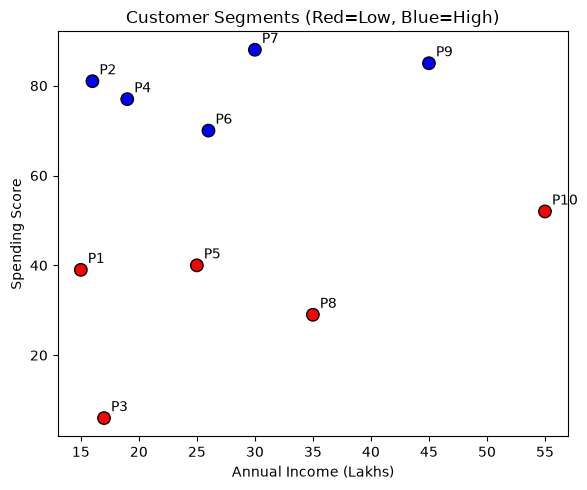

In [10]:
def scatter_plot(points, labels):
    colors = ['red' if l == 'Low' else 'blue' for l in labels]
    plt.figure(figsize=(6, 5))
    plt.scatter(points[:, 0], points[:, 1], c=colors, s=80, edgecolors='k')
    for i, (x, y) in enumerate(points):
        plt.annotate(f'P{i+1}', (x, y), textcoords='offset points', xytext=(5, 5))
    plt.xlabel('Annual Income (Lakhs)')
    plt.ylabel('Spending Score')
    plt.title('Customer Segments (Red=Low, Blue=High)')
    plt.tight_layout()
    plt.show()

scatter_plot(points_knn, labels_knn)

In [11]:
def euclidean_distance(p1, p2):
    return np.sqrt(np.sum((np.array(p1) - np.array(p2)) ** 2))

def get_k_neighbours(train, labels, query, k):
    dists = [(euclidean_distance(train[i], query), labels[i]) for i in range(len(train))]
    dists.sort(key=lambda x: x[0])
    return dists[:k]

def knn_predict(train, labels, query, k):
    neighbours = get_k_neighbours(train, labels, query, k)
    votes = Counter(label for _, label in neighbours)
    return votes.most_common(1)[0][0]

query = [28, 60]
for k in [1, 3, 5]:
    pred = knn_predict(points_knn, labels_knn, query, k)
    print(f'K={k}: {pred}')

K=1: High
K=3: High
K=5: High


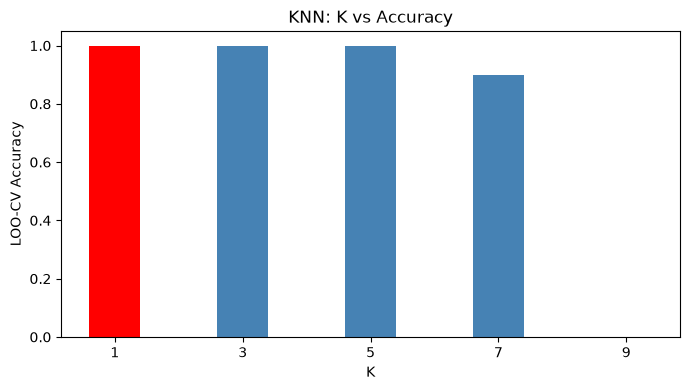

Best K = 1


In [12]:
def knn_accuracy(points, labels, k):
    correct = 0
    for i in range(len(points)):
        train  = np.delete(points, i, axis=0)
        tr_lbl = labels[:i] + labels[i+1:]
        pred   = knn_predict(train, tr_lbl, points[i], k)
        if pred == labels[i]:
            correct += 1
    return correct / len(points)

def plot_k_vs_accuracy_knn(points, labels):
    k_vals = list(range(1, 10, 2))
    accs   = [knn_accuracy(points, labels, k) for k in k_vals]
    best_k = k_vals[accs.index(max(accs))]
    colors = ['red' if k == best_k else 'steelblue' for k in k_vals]
    plt.figure(figsize=(7, 4))
    plt.bar(k_vals, accs, color=colors)
    plt.xlabel('K')
    plt.ylabel('LOO-CV Accuracy')
    plt.title('KNN: K vs Accuracy')
    plt.xticks(k_vals)
    plt.tight_layout()
    plt.show()
    print(f'Best K = {best_k}')

plot_k_vs_accuracy_knn(points_knn, labels_knn)

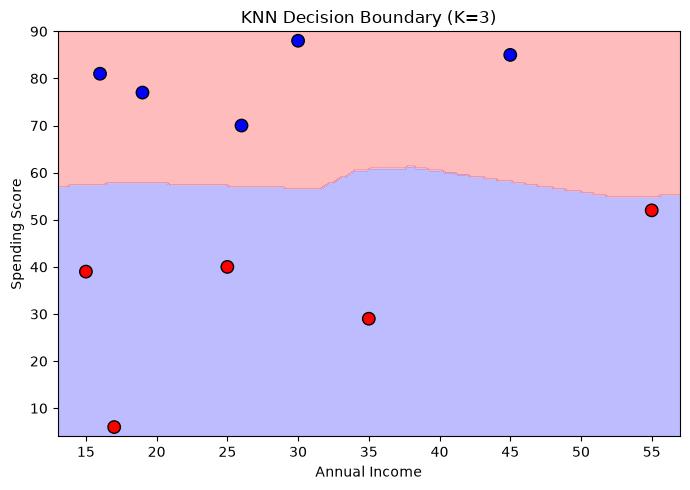

In [13]:
def decision_boundary_plot(points, labels, k):
    x_min, x_max = points[:,0].min()-2, points[:,0].max()+2
    y_min, y_max = points[:,1].min()-2, points[:,1].max()+2
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    grid   = np.c_[xx.ravel(), yy.ravel()]
    preds  = np.array([knn_predict(points, labels, g, k) for g in grid])
    zz     = (preds == 'High').astype(int).reshape(xx.shape)
    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, zz, alpha=0.3, cmap='bwr')
    colors = ['red' if l == 'Low' else 'blue' for l in labels]
    plt.scatter(points[:,0], points[:,1], c=colors, s=80, edgecolors='k', zorder=3)
    plt.xlabel('Annual Income')
    plt.ylabel('Spending Score')
    plt.title(f'KNN Decision Boundary (K={k})')
    plt.tight_layout()
    plt.show()

decision_boundary_plot(points_knn, labels_knn, k=3)

---
## PAPER 3 — ID3

In [14]:
data_id3 = [
    {'Age':'<=30', 'Income':'High',   'Student':'No',  'Credit':'Fair',      'BuysComputer':'No'},
    {'Age':'<=30', 'Income':'High',   'Student':'No',  'Credit':'Excellent', 'BuysComputer':'No'},
    {'Age':'31-40','Income':'High',   'Student':'No',  'Credit':'Fair',      'BuysComputer':'Yes'},
    {'Age':'>40',  'Income':'Medium', 'Student':'No',  'Credit':'Fair',      'BuysComputer':'Yes'},
    {'Age':'>40',  'Income':'Low',    'Student':'Yes', 'Credit':'Fair',      'BuysComputer':'Yes'},
    {'Age':'>40',  'Income':'Low',    'Student':'Yes', 'Credit':'Excellent', 'BuysComputer':'No'},
    {'Age':'31-40','Income':'Low',    'Student':'Yes', 'Credit':'Excellent', 'BuysComputer':'Yes'},
    {'Age':'<=30', 'Income':'Medium', 'Student':'No',  'Credit':'Fair',      'BuysComputer':'No'},
    {'Age':'<=30', 'Income':'Low',    'Student':'Yes', 'Credit':'Fair',      'BuysComputer':'Yes'},
    {'Age':'>40',  'Income':'Medium', 'Student':'Yes', 'Credit':'Fair',      'BuysComputer':'Yes'},
    {'Age':'<=30', 'Income':'Medium', 'Student':'Yes', 'Credit':'Excellent', 'BuysComputer':'Yes'},
    {'Age':'31-40','Income':'Medium', 'Student':'No',  'Credit':'Excellent', 'BuysComputer':'Yes'},
    {'Age':'31-40','Income':'High',   'Student':'Yes', 'Credit':'Fair',      'BuysComputer':'Yes'},
    {'Age':'>40',  'Income':'Medium', 'Student':'No',  'Credit':'Excellent', 'BuysComputer':'No'},
]

In [15]:
def entropy(labels):
    total = len(labels)
    counts = Counter(labels)
    return -sum((c/total) * np.log2(c/total) for c in counts.values() if c > 0)

def information_gain(data, feature, target):
    total  = len(data)
    base_e = entropy([row[target] for row in data])
    values = set(row[feature] for row in data)
    weighted = sum(
        (len(subset := [row for row in data if row[feature] == v]) / total)
        * entropy([row[target] for row in subset])
        for v in values
    )
    return base_e - weighted

def best_split(data, features, target):
    gains = {f: information_gain(data, f, target) for f in features}
    return max(gains, key=gains.get), gains

features_id3 = ['Age', 'Income', 'Student', 'Credit']
best, gains = best_split(data_id3, features_id3, 'BuysComputer')
print('Best split:', best)
for f, g in gains.items():
    print(f'  IG({f}) = {g:.4f}')

Best split: Age
  IG(Age) = 0.2467
  IG(Income) = 0.0292
  IG(Student) = 0.1518
  IG(Credit) = 0.0481


In [16]:
def build_id3_tree(data, features, target):
    labels = [row[target] for row in data]
    # Base case: pure node
    if len(set(labels)) == 1:
        return labels[0]
    # Base case: no features left
    if not features:
        return Counter(labels).most_common(1)[0][0]
    best, _ = best_split(data, features, target)
    tree = {best: {}}
    for val in set(row[best] for row in data):
        subset = [row for row in data if row[best] == val]
        remaining = [f for f in features if f != best]
        tree[best][val] = build_id3_tree(subset, remaining, target)
    return tree

tree_id3 = build_id3_tree(data_id3, features_id3, 'BuysComputer')
print(tree_id3)

{'Age': {'<=30': {'Student': {'No': 'No', 'Yes': 'Yes'}}, '>40': {'Credit': {'Excellent': 'No', 'Fair': 'Yes'}}, '31-40': 'Yes'}}


In [17]:
def predict_id3(tree, instance):
    if not isinstance(tree, dict):
        return tree
    feature = next(iter(tree))
    val = instance.get(feature)
    subtree = tree[feature].get(val)
    if subtree is None:
        return None
    return predict_id3(subtree, instance)

def print_tree(tree, indent=0):
    if not isinstance(tree, dict):
        print(' ' * indent + f'=> {tree}')
        return
    feature = next(iter(tree))
    print(' ' * indent + f'[{feature}]')
    for val, subtree in tree[feature].items():
        print(' ' * (indent + 2) + f'-- {val}:')
        print_tree(subtree, indent + 4)

print_tree(tree_id3)

[Age]
  -- <=30:
    [Student]
      -- No:
        => No
      -- Yes:
        => Yes
  -- >40:
    [Credit]
      -- Excellent:
        => No
      -- Fair:
        => Yes
  -- 31-40:
    => Yes


---
## PAPER 4 — CART

In [18]:
data_cart = [
    {'Outlook':'Sunny',    'Temperature':'Hot',  'Humidity':'High',   'Wind':'Weak',   'PlayTennis':'No'},
    {'Outlook':'Sunny',    'Temperature':'Hot',  'Humidity':'High',   'Wind':'Strong', 'PlayTennis':'No'},
    {'Outlook':'Overcast', 'Temperature':'Hot',  'Humidity':'High',   'Wind':'Weak',   'PlayTennis':'Yes'},
    {'Outlook':'Rain',     'Temperature':'Mild', 'Humidity':'High',   'Wind':'Weak',   'PlayTennis':'Yes'},
    {'Outlook':'Rain',     'Temperature':'Cool', 'Humidity':'Normal', 'Wind':'Weak',   'PlayTennis':'Yes'},
    {'Outlook':'Rain',     'Temperature':'Cool', 'Humidity':'Normal', 'Wind':'Strong', 'PlayTennis':'No'},
    {'Outlook':'Overcast', 'Temperature':'Cool', 'Humidity':'Normal', 'Wind':'Strong', 'PlayTennis':'Yes'},
    {'Outlook':'Sunny',    'Temperature':'Mild', 'Humidity':'High',   'Wind':'Weak',   'PlayTennis':'No'},
    {'Outlook':'Sunny',    'Temperature':'Cool', 'Humidity':'Normal', 'Wind':'Weak',   'PlayTennis':'Yes'},
    {'Outlook':'Rain',     'Temperature':'Mild', 'Humidity':'Normal', 'Wind':'Weak',   'PlayTennis':'Yes'},
    {'Outlook':'Sunny',    'Temperature':'Mild', 'Humidity':'Normal', 'Wind':'Strong', 'PlayTennis':'Yes'},
    {'Outlook':'Overcast', 'Temperature':'Mild', 'Humidity':'High',   'Wind':'Strong', 'PlayTennis':'Yes'},
    {'Outlook':'Overcast', 'Temperature':'Hot',  'Humidity':'Normal', 'Wind':'Weak',   'PlayTennis':'Yes'},
    {'Outlook':'Rain',     'Temperature':'Mild', 'Humidity':'High',   'Wind':'Strong', 'PlayTennis':'No'},
]

In [19]:
def gini(labels):
    total = len(labels)
    counts = Counter(labels)
    return 1 - sum((c / total) ** 2 for c in counts.values())

def gini_split(data, feature, target):
    total  = len(data)
    values = list(set(row[feature] for row in data))
    best_gini, best_split_val = float('inf'), None
    # Try all binary partitions
    from itertools import combinations
    for r in range(1, len(values)):
        for left_vals in combinations(values, r):
            left  = [row for row in data if row[feature] in left_vals]
            right = [row for row in data if row[feature] not in left_vals]
            if not left or not right:
                continue
            wg = (len(left)/total)*gini([r[target] for r in left]) + \
                 (len(right)/total)*gini([r[target] for r in right])
            if wg < best_gini:
                best_gini, best_split_val = wg, left_vals
    return best_gini, best_split_val

def best_cart_split(data, features, target):
    best_feature, best_gini_val, best_sv = None, float('inf'), None
    for f in features:
        g, sv = gini_split(data, f, target)
        if g < best_gini_val:
            best_gini_val, best_feature, best_sv = g, f, sv
    return best_feature, best_sv, best_gini_val

features_cart = ['Outlook', 'Temperature', 'Humidity', 'Wind']
f, sv, g = best_cart_split(data_cart, features_cart, 'PlayTennis')
print(f'Best split: {f} | Left values: {sv} | Weighted Gini: {g:.4f}')

Best split: Outlook | Left values: ('Overcast',) | Weighted Gini: 0.3571


In [20]:
def build_cart_tree(data, features, target, max_depth=None, depth=0):
    labels = [row[target] for row in data]
    if len(set(labels)) == 1:
        return labels[0]
    if not features or (max_depth is not None and depth >= max_depth):
        return Counter(labels).most_common(1)[0][0]
    feature, split_vals, _ = best_cart_split(data, features, target)
    if split_vals is None:
        return Counter(labels).most_common(1)[0][0]
    left  = [row for row in data if row[feature] in split_vals]
    right = [row for row in data if row[feature] not in split_vals]
    return {
        feature: {
            'left_vals': split_vals,
            'left':  build_cart_tree(left,  features, target, max_depth, depth+1),
            'right': build_cart_tree(right, features, target, max_depth, depth+1),
        }
    }

tree_cart = build_cart_tree(data_cart, features_cart, 'PlayTennis')
print(tree_cart)

{'Outlook': {'left_vals': ('Overcast',), 'left': 'Yes', 'right': {'Humidity': {'left_vals': ('High',), 'left': {'Outlook': {'left_vals': ('Sunny',), 'left': 'No', 'right': {'Wind': {'left_vals': ('Weak',), 'left': 'Yes', 'right': 'No'}}}}, 'right': {'Wind': {'left_vals': ('Weak',), 'left': 'Yes', 'right': {'Outlook': {'left_vals': ('Sunny',), 'left': 'Yes', 'right': 'No'}}}}}}}}


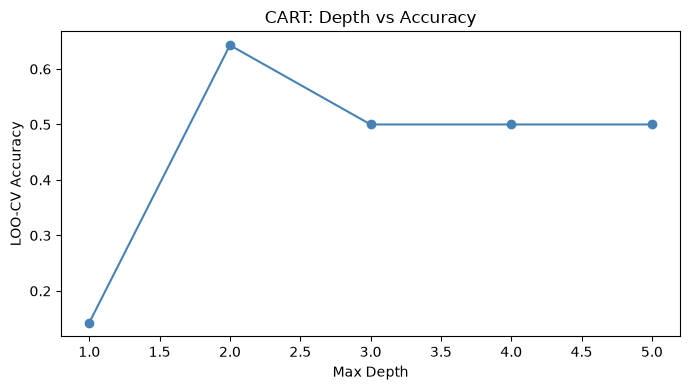

In [21]:
def predict_cart(tree, instance):
    if not isinstance(tree, dict):
        return tree
    feature = next(iter(tree))
    node = tree[feature]
    if instance[feature] in node['left_vals']:
        return predict_cart(node['left'], instance)
    else:
        return predict_cart(node['right'], instance)

def plot_gini_vs_depth(data, features, target):
    depths = list(range(1, 6))
    accs   = []
    for d in depths:
        correct = 0
        for i in range(len(data)):
            train = data[:i] + data[i+1:]
            test  = data[i]
            tree  = build_cart_tree(train, features, target, max_depth=d)
            instance = {k: v for k, v in test.items() if k != target}
            if predict_cart(tree, instance) == test[target]:
                correct += 1
        accs.append(correct / len(data))
    plt.figure(figsize=(7, 4))
    plt.plot(depths, accs, marker='o', color='steelblue')
    plt.xlabel('Max Depth')
    plt.ylabel('LOO-CV Accuracy')
    plt.title('CART: Depth vs Accuracy')
    plt.tight_layout()
    plt.show()

plot_gini_vs_depth(data_cart, features_cart, 'PlayTennis')

---
## PAPER 5 — C4.5

In [ ]:
data_c45 = data_id3.copy()  # Same Buys Computer dataset
features_c45 = ['Age', 'Income', 'Student', 'Credit']

In [ ]:
def split_information(data, feature):
    total  = len(data)
    values = set(row[feature] for row in data)
    return -sum(
        (len(subset := [row for row in data if row[feature] == v]) / total)
        * np.log2(len(subset) / total)
        for v in values
        if len([row for row in data if row[feature] == v]) > 0
    )

def gain_ratio(data, feature, target):
    si = split_information(data, feature)
    if si == 0:
        return 0
    return information_gain(data, feature, target) / si

for f in features_c45:
    print(f'GainRatio({f}) = {gain_ratio(data_c45, f, "BuysComputer"):.4f}')

In [ ]:
def best_c45_split(data, features, target):
    # C4.5 heuristic: only consider features with above-average IG
    igs = {f: information_gain(data, f, target) for f in features}
    avg_ig = np.mean(list(igs.values()))
    candidates = [f for f in features if igs[f] >= avg_ig]
    if not candidates:
        candidates = features
    grs = {f: gain_ratio(data, f, target) for f in candidates}
    return max(grs, key=grs.get), grs

best_c45_split(data_c45, features_c45, 'BuysComputer')

In [ ]:
def build_c45_tree(data, features, target):
    labels = [row[target] for row in data]
    if len(set(labels)) == 1:
        return labels[0]
    if not features:
        return Counter(labels).most_common(1)[0][0]
    best, _ = best_c45_split(data, features, target)
    tree = {best: {}}
    for val in set(row[best] for row in data):
        subset    = [row for row in data if row[best] == val]
        remaining = [f for f in features if f != best]
        tree[best][val] = build_c45_tree(subset, remaining, target)
    return tree

tree_c45 = build_c45_tree(data_c45, features_c45, 'BuysComputer')
print_tree(tree_c45)

In [ ]:
def predict_c45(tree, instance):
    return predict_id3(tree, instance)  # same traversal logic

def c45_accuracy(data, features, target):
    correct = 0
    for i in range(len(data)):
        train = data[:i] + data[i+1:]
        test  = data[i]
        tree  = build_c45_tree(train, features, target)
        instance = {k: v for k, v in test.items() if k != target}
        if predict_c45(tree, instance) == test[target]:
            correct += 1
    return correct / len(data)

print(f'C4.5 LOO-CV Accuracy: {c45_accuracy(data_c45, features_c45, "BuysComputer"):.2%}')

In [ ]:
def compare_trees(data, features, target):
    print('=== ID3 Tree ===')
    tree_i = build_id3_tree(data, features, target)
    print_tree(tree_i)

    print('\n=== C4.5 Tree ===')
    tree_c = build_c45_tree(data, features, target)
    print_tree(tree_c)

    # LOO-CV for ID3
    correct_id3 = 0
    for i in range(len(data)):
        train = data[:i] + data[i+1:]
        test  = data[i]
        t     = build_id3_tree(train, features, target)
        inst  = {k: v for k, v in test.items() if k != target}
        if predict_id3(t, inst) == test[target]:
            correct_id3 += 1

    acc_id3 = correct_id3 / len(data)
    acc_c45 = c45_accuracy(data, features, target)

    print(f'\nID3  LOO-CV Accuracy: {acc_id3:.2%}')
    print(f'C4.5 LOO-CV Accuracy: {acc_c45:.2%}')

compare_trees(data_c45, features_c45, 'BuysComputer')

In [3]:
import inspect
import sklearn
sklearn??

Type:        module
String form: <module 'sklearn' from '/usr/lib/python3.14/site-packages/sklearn/__init__.py'>
File:        /usr/lib/python3.14/site-packages/sklearn/__init__.py
Source:     
"""Configure global settings and get information about the working environment."""

# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

# Machine learning module for Python
# ==================================
#
# sklearn is a Python module integrating classical machine
# learning algorithms in the tightly-knit world of scientific Python
# packages (numpy, scipy, matplotlib).
#
# It aims to provide simple and efficient solutions to learning problems
# that are accessible to everybody and reusable in various contexts:
# machine-learning as a versatile tool for science and engineering.
#
# See https://scikit-learn.org for complete documentation.

import importlib as _importlib
import logging
import os
import random

from sklearn._config import config_context, get_config,